# Programa Ejemplo para Realizar Aprendizaje Supervisado utilizando aprendizaje profundo

## Etapa 1: Carga de los datos.

Antes de comenzar a definir la red neuronal, cargamos la base de datos de interés. Para este ejemplo, usaremos la base de datos MNIST, la cual consiste en identificar dígitos escritos a mano alzada. Esta base de datos configura un problema de 10 clases, una clase por cada dígito numérico (0-9).

Se cargan las librerías necesarias.

In [1]:
import torch
import torch.nn as nn
import matplotlib.pyplot as plt
from torchvision import datasets

Se carga la base de datos y se divide en los conjuntos de entrenamiento y prueba. Hay 60000 imágenes para el entrenamiento y 10000 en el conjunto de prueba.

In [2]:
mnist_train = datasets.MNIST(root="data", train=True, download=True)
mnist_test = datasets.MNIST(root="data", train=False, download=True)

# .data guarda las imágenes y .targets las etiquetas (0-9), ya como tensores de PyTorch
x_train, y_train = mnist_train.data, mnist_train.targets
x_test, y_test = mnist_test.data, mnist_test.targets

In [3]:
print(x_train.shape)

torch.Size([60000, 28, 28])


Las imágenes tienen tamaño de 28x28. A continuación, se muestran algunos ejemplos.

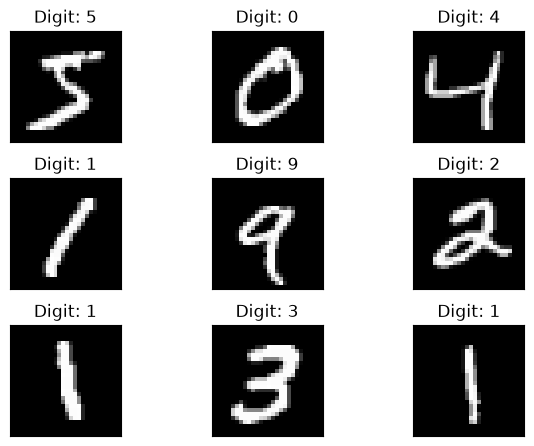

In [4]:
fig = plt.figure()
for i in range(9):
    plt.subplot(3, 3, i+1)
    plt.tight_layout()
    plt.imshow(x_train[i], cmap="gray", interpolation="none")
    plt.title("Digit: {}".format(y_train[i].item()))
    plt.xticks([])
    plt.yticks([])
plt.show()

Dado que este ejercicio es introductorio solo usaremos la forma más básica de una red neuronal, denominada densa. Esta versión no tiene la capacidad de manipular imágenes en su forma original. Así, aplicaremos una etapa de preprocesamiento a cada imagen con el fin de que las imágenes sean compatibles con las entradas de la red.

In [5]:
# Cada imagen de 28x28 se aplasta en un vector de 784 valores y los píxeles (0 a 255) se
# dividen entre 255 para que queden entre 0 y 1. El -1 significa "calcula esta dimensión
# por mí": se conservan todas las imágenes.
x_train_flat = x_train.reshape(-1, 28*28).float() / 255
x_test_flat = x_test.reshape(-1, 28*28).float() / 255

La operación llevada a cabo se denomina "aplastamiento" y consiste en convertir un arreglo de dos o más dimensiones en uno de una dimensión. El aplastamiento o flatten consiste en unir las filas del arreglo una a continuación de otra.

In [6]:
print(x_train_flat.shape)

torch.Size([60000, 784])


Se mantienen las mismas 60000 imágenes del entrenamiento y se obtienen 784 atributos luego del proceso de aplastamiento. 28*28=784.

## Etapa 2: Definición de la red.

Ahora podemos empezar a construir la red neuronal para resolver el problema de clasificación planteado. En PyTorch una red se puede definir de varias formas; en este ejemplo usaremos `nn.Sequential`, que apila las capas en orden.

### 2.1 Definición de la red usando nn.Sequential.

Se define una red con tres capas: dos ocultas y una de salida. Para este ejemplo el tipo de capas usada es la densa (`nn.Linear`); en unidades posteriores usaremos otro tipo de capas como las convolucionales y las recurrentes.

In [7]:
# Se usa la GPU si está disponible
device = torch.device("cuda" if torch.cuda.is_available() else "cpu")
torch.manual_seed(0)

model = nn.Sequential(
    # La primera capa recibe 784 valores (la dimensión de los datos) y tiene
    # 1024 unidades con activación ReLU.
    nn.Linear(784, 1024),
    nn.ReLU(),
    # La segunda capa presenta 512 unidades con activación ReLU.
    nn.Linear(1024, 512),
    nn.ReLU(),
    # La tercera capa corresponde a la capa de salida. Como es un problema de clasificación
    # de múltiples clases, la capa de salida debe tener tantas unidades como clases (10).
    # No se aplica softmax: la función de costo de PyTorch lo hace internamente.
    nn.Linear(512, 10),
).to(device)

In [8]:
# Con print(model) podemos verificar las capas que definimos y, contando los parámetros,
# la cantidad de parámetros de cada capa.
print(model)
print()
for name, p in model.named_parameters():
    print(f"{name:12s} {str(tuple(p.shape)):16s} {p.numel():>10,}")
print(f"\nTotal de parámetros: {sum(p.numel() for p in model.parameters()):,}")

Sequential(
  (0): Linear(in_features=784, out_features=1024, bias=True)
  (1): ReLU()
  (2): Linear(in_features=1024, out_features=512, bias=True)
  (3): ReLU()
  (4): Linear(in_features=512, out_features=10, bias=True)
)

0.weight     (1024, 784)         802,816
0.bias       (1024,)               1,024
2.weight     (512, 1024)         524,288
2.bias       (512,)                  512
4.weight     (10, 512)             5,120
4.bias       (10,)                    10

Total de parámetros: 1,333,770


In [9]:
# Se define la función de costo, el optimizador y la métrica usada para medir el rendimiento.
# 1. Para el loss se usa CrossEntropyLoss dado que es un problema de clasificación multi-clase.
# 2. Utilizamos el optimizador SGD, el cual es un algoritmo basado en gradiente.
# 3. Finalmente, se usa el accuracy para medir el rendimiento.
loss_fn = nn.CrossEntropyLoss()
optimizer = torch.optim.SGD(model.parameters(), lr=0.01)

def accuracy(logits, y):
    return (logits.argmax(dim=1) == y).float().mean().item()

Ahora, es momento de entrenar la red neuronal, lo cual corresponde a calcular los parámetros de la red. En cada época se repiten estos pasos:

1. `optimizer.zero_grad()`: se borran los gradientes de la iteración anterior.
2. `model(x)`: la red calcula su predicción con los datos de entrenamiento.
3. `loss_fn(logits, y)`: se mide el error entre la predicción y la etiqueta real.
4. `loss.backward()`: se calcula el gradiente del error respecto a cada parámetro.
5. `optimizer.step()`: se actualizan los parámetros con esos gradientes.

El número de épocas obedece a la cantidad de repeticiones del entrenamiento. El tamaño del batch será un parámetro que discutiremos en la siguiente unidad; por ahora lo fijamos para que sea igual a la cantidad de muestras en el conjunto de entrenamiento, es decir, se usan las 60000 imágenes de una vez. Al final de cada época también medimos el desempeño en el conjunto de prueba.

In [10]:
epochs = 20

x_train_dev, y_train_dev = x_train_flat.to(device), y_train.to(device)
x_test_dev, y_test_dev = x_test_flat.to(device), y_test.to(device)

history = {"loss": [], "accuracy": [], "val_loss": [], "val_accuracy": []}

for epoch in range(epochs):
    # --- entrenamiento: las 60000 imágenes de una vez ---
    model.train()
    optimizer.zero_grad()
    logits = model(x_train_dev)
    loss = loss_fn(logits, y_train_dev)
    loss.backward()
    optimizer.step()
    history["loss"].append(loss.item())
    history["accuracy"].append(accuracy(logits, y_train_dev))

    # --- prueba: solo se mide, sin calcular gradientes ---
    model.eval()
    with torch.no_grad():
        test_logits = model(x_test_dev)
        history["val_loss"].append(loss_fn(test_logits, y_test_dev).item())
        history["val_accuracy"].append(accuracy(test_logits, y_test_dev))

    print(f"Epoch {epoch+1}/{epochs} - loss: {history['loss'][-1]:.4f} - accuracy: {history['accuracy'][-1]:.4f}"
          f" - val_loss: {history['val_loss'][-1]:.4f} - val_accuracy: {history['val_accuracy'][-1]:.4f}")

Epoch 1/20 - loss: 2.3054 - accuracy: 0.1005 - val_loss: 2.3050 - val_accuracy: 0.1011
Epoch 2/20 - loss: 2.3049 - accuracy: 0.1026 - val_loss: 2.3044 - val_accuracy: 0.1035


Epoch 3/20 - loss: 2.3043 - accuracy: 0.1042 - val_loss: 2.3038 - val_accuracy: 0.1062
Epoch 4/20 - loss: 2.3037 - accuracy: 0.1059 - val_loss: 2.3032 - val_accuracy: 0.1090
Epoch 5/20 - loss: 2.3031 - accuracy: 0.1077 - val_loss: 2.3027 - val_accuracy: 0.1114
Epoch 6/20 - loss: 2.3026 - accuracy: 0.1094 - val_loss: 2.3021 - val_accuracy: 0.1145
Epoch 7/20 - loss: 2.3020 - accuracy: 0.1114 - val_loss: 2.3015 - val_accuracy: 0.1162


Epoch 8/20 - loss: 2.3014 - accuracy: 0.1136 - val_loss: 2.3009 - val_accuracy: 0.1190
Epoch 9/20 - loss: 2.3008 - accuracy: 0.1160 - val_loss: 2.3003 - val_accuracy: 0.1212


Epoch 10/20 - loss: 2.3003 - accuracy: 0.1184 - val_loss: 2.2997 - val_accuracy: 0.1230
Epoch 11/20 - loss: 2.2997 - accuracy: 0.1203 - val_loss: 2.2991 - val_accuracy: 0.1253
Epoch 12/20 - loss: 2.2991 - accuracy: 0.1227 - val_loss: 2.2985 - val_accuracy: 0.1288
Epoch 13/20 - loss: 2.2986 - accuracy: 0.1251 - val_loss: 2.2980 - val_accuracy: 0.1303
Epoch 14/20 - loss: 2.2980 - accuracy: 0.1278 - val_loss: 2.2974 - val_accuracy: 0.1345


Epoch 15/20 - loss: 2.2974 - accuracy: 0.1301 - val_loss: 2.2968 - val_accuracy: 0.1370
Epoch 16/20 - loss: 2.2969 - accuracy: 0.1333 - val_loss: 2.2962 - val_accuracy: 0.1402


Epoch 17/20 - loss: 2.2963 - accuracy: 0.1356 - val_loss: 2.2956 - val_accuracy: 0.1429
Epoch 18/20 - loss: 2.2957 - accuracy: 0.1385 - val_loss: 2.2950 - val_accuracy: 0.1451
Epoch 19/20 - loss: 2.2951 - accuracy: 0.1415 - val_loss: 2.2944 - val_accuracy: 0.1475
Epoch 20/20 - loss: 2.2946 - accuracy: 0.1445 - val_loss: 2.2939 - val_accuracy: 0.1504


In [11]:
model.eval()
with torch.no_grad():
    test_logits = model(x_test_dev)
    test_loss = loss_fn(test_logits, y_test_dev).item()
    test_acc = accuracy(test_logits, y_test_dev)
print("test_acc:", test_acc)

test_acc: 0.15039999783039093


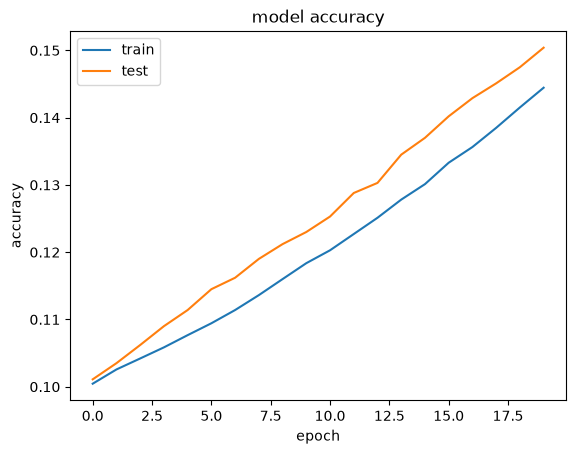

In [12]:
# Graficar los resultados
plt.plot(history["accuracy"])
plt.plot(history["val_accuracy"])
plt.title("model accuracy")
plt.ylabel("accuracy")
plt.xlabel("epoch")
plt.legend(["train", "test"], loc="upper left")
plt.show()

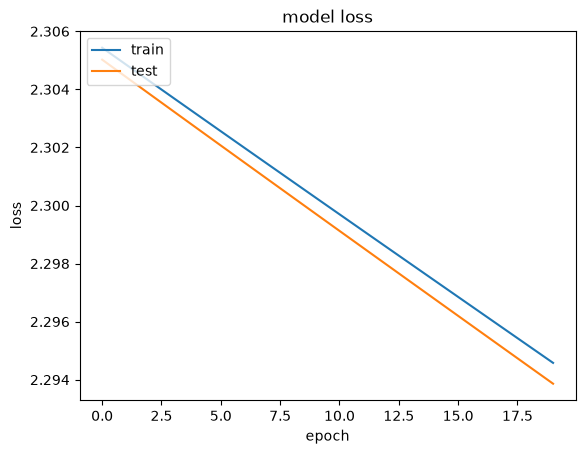

In [13]:
plt.plot(history["loss"])
plt.plot(history["val_loss"])
plt.title("model loss")
plt.ylabel("loss")
plt.xlabel("epoch")
plt.legend(["train", "test"], loc="upper left")
plt.show()